# 1. Problem

Recover the full four-dimensional transverse probability distribution of a measured proton beam from **24 wire-scanner profiles**: two optical configurations, four stations and three directions. The distribution includes position–direction and cross-plane correlations. A separate two-dimensional reconstruction would change the physical problem.

No independent four-dimensional beam density is available. Reproduced source results are method outputs, while the benchmark evaluates individual observation agreement, probability, a Gaussian-prior entropy condition and a coordinate-consistency condition. The selected method is an explicitly corrected source variant (V2); the original V1 computation is retained as a diagnosed comparison.

In [1]:
%matplotlib inline
from pathlib import Path
import sys,time,json,importlib.util
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=Path.cwd()
if not (ROOT/'src').exists():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.main import run
from src.preprocessing import load_observations,preprocess,COORDS
from src.physics_model import grid_points,projected_coordinates,probability,emittances
from src.solvers import sample_grid,simulated_profile
from src import visualization as vis
vis.style()
raw=load_observations(ROOT/'data/raw_data.npz')
measured,moments=preprocess(raw)
source=np.load(ROOT/'evaluation/baseline_reference.npz',allow_pickle=False)
old=np.load(ROOT/'notebooks/reference_outputs/source_v1_diagnostic.npz',allow_pickle=False)
source_profiles=np.load(ROOT/'notebooks/reference_outputs/source_projection_measurements.npz',allow_pickle=False)
source_eval=np.load(ROOT/'notebooks/reference_outputs/source_eval_metrics.npz',allow_pickle=False)
spec=importlib.util.spec_from_file_location('review_judge',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
observed,T,S=judge.observations(ROOT/'data/raw_data.npz')
thresholds=judge.configuration(ROOT/'evaluation/metrics.json')
start=time.perf_counter()
fresh=run(ROOT)
elapsed=time.perf_counter()-start
print({'fresh_complete_inverse_seconds':elapsed,'complete_sweeps':fresh['history'].shape[0]-1,'profiles_per_sweep':24,'particles_per_projection_update':1000000,'four_dimensional_voxels':35**4})
assert fresh['history'].shape==(6,24,100)
np.testing.assert_allclose(measured,observed,rtol=1e-12,atol=1e-12)

LOCAL_FULL_EPOCH 1
LOCAL_FULL_EPOCH 2
LOCAL_FULL_EPOCH 3
LOCAL_FULL_EPOCH 4
LOCAL_FULL_EPOCH 5
{'fresh_complete_inverse_seconds': 118.53202609997243, 'complete_sweeps': 5, 'profiles_per_sweep': 24, 'particles_per_projection_update': 1000000, 'four_dimensional_voxels': 1500625}


# 2. Data

Native positions, signal amplitudes and raw statistical means/RMS widths retain float64 precision. A visible mask marks only format padding. The means and RMS widths are acquisition-reported **raw statistics**, not the Gaussian-fit columns and not a reconstruction fitted by this task. They are used to center profiles and infer the prior covariance.

The first and second acquisition headers state 2024-08-19 at 16:50:33 and 17:09:09 EDT. Eight known optics matrices carry physical coordinates $(X,X',Y,Y')$ in(mm,mrad,mm,mrad). All 24 observations are retained. The normalized profile processing uses the declared signal threshold, jump exclusion, interpolation and Gaussian smoothing; the widths are not silently recomputed using that different protocol.

The following two figures preserve all linear and logarithmic preprocessing views. Curves are divided by their own peak for shape comparison. Nonpositive values are omitted **only in the logarithmic display**; original signs and zeros remain in the observations and linear plots.

findfont: Failed to find font weight semibold, now using 700.


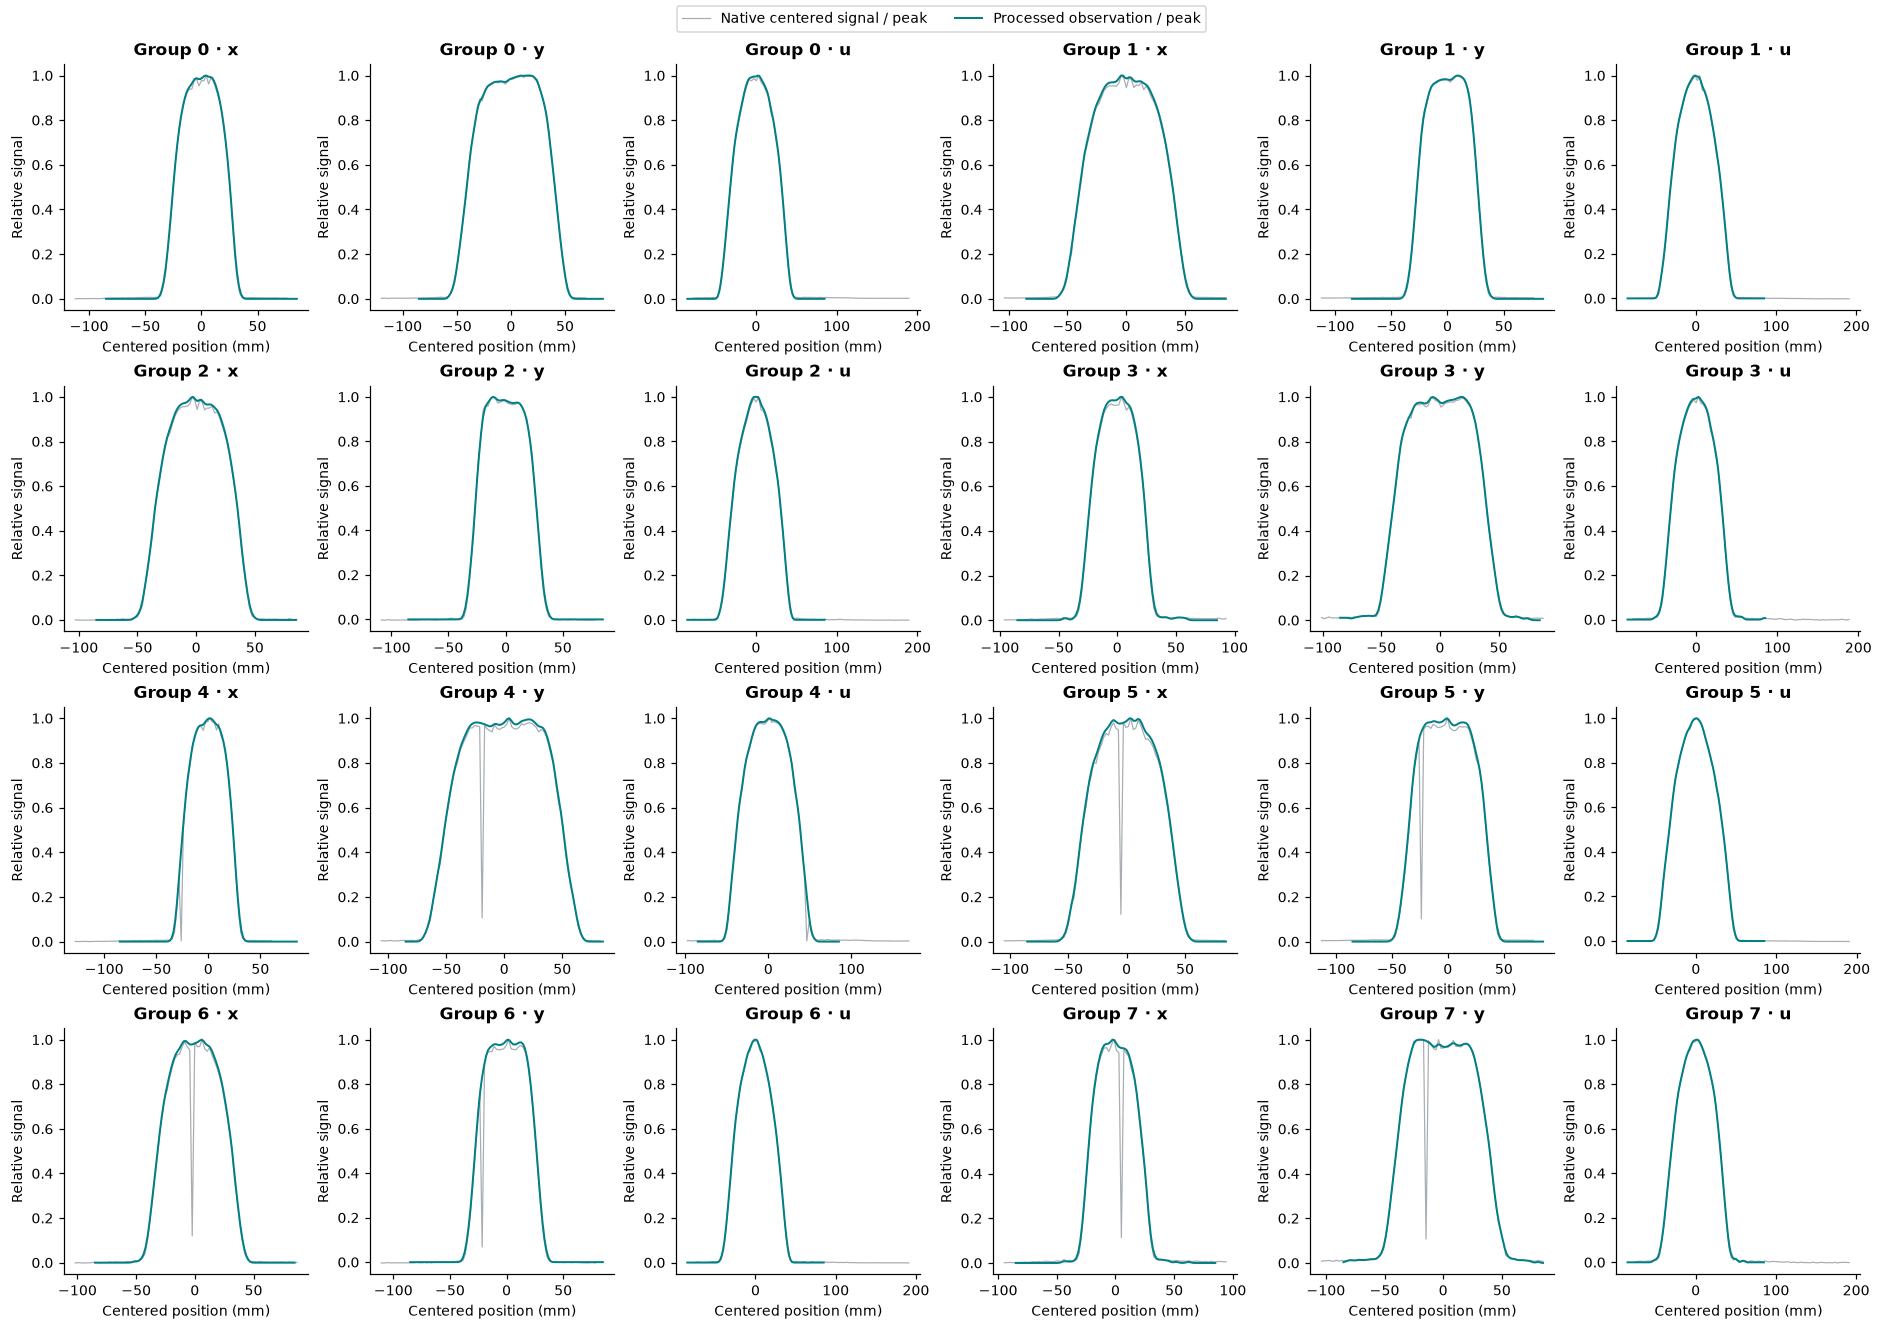

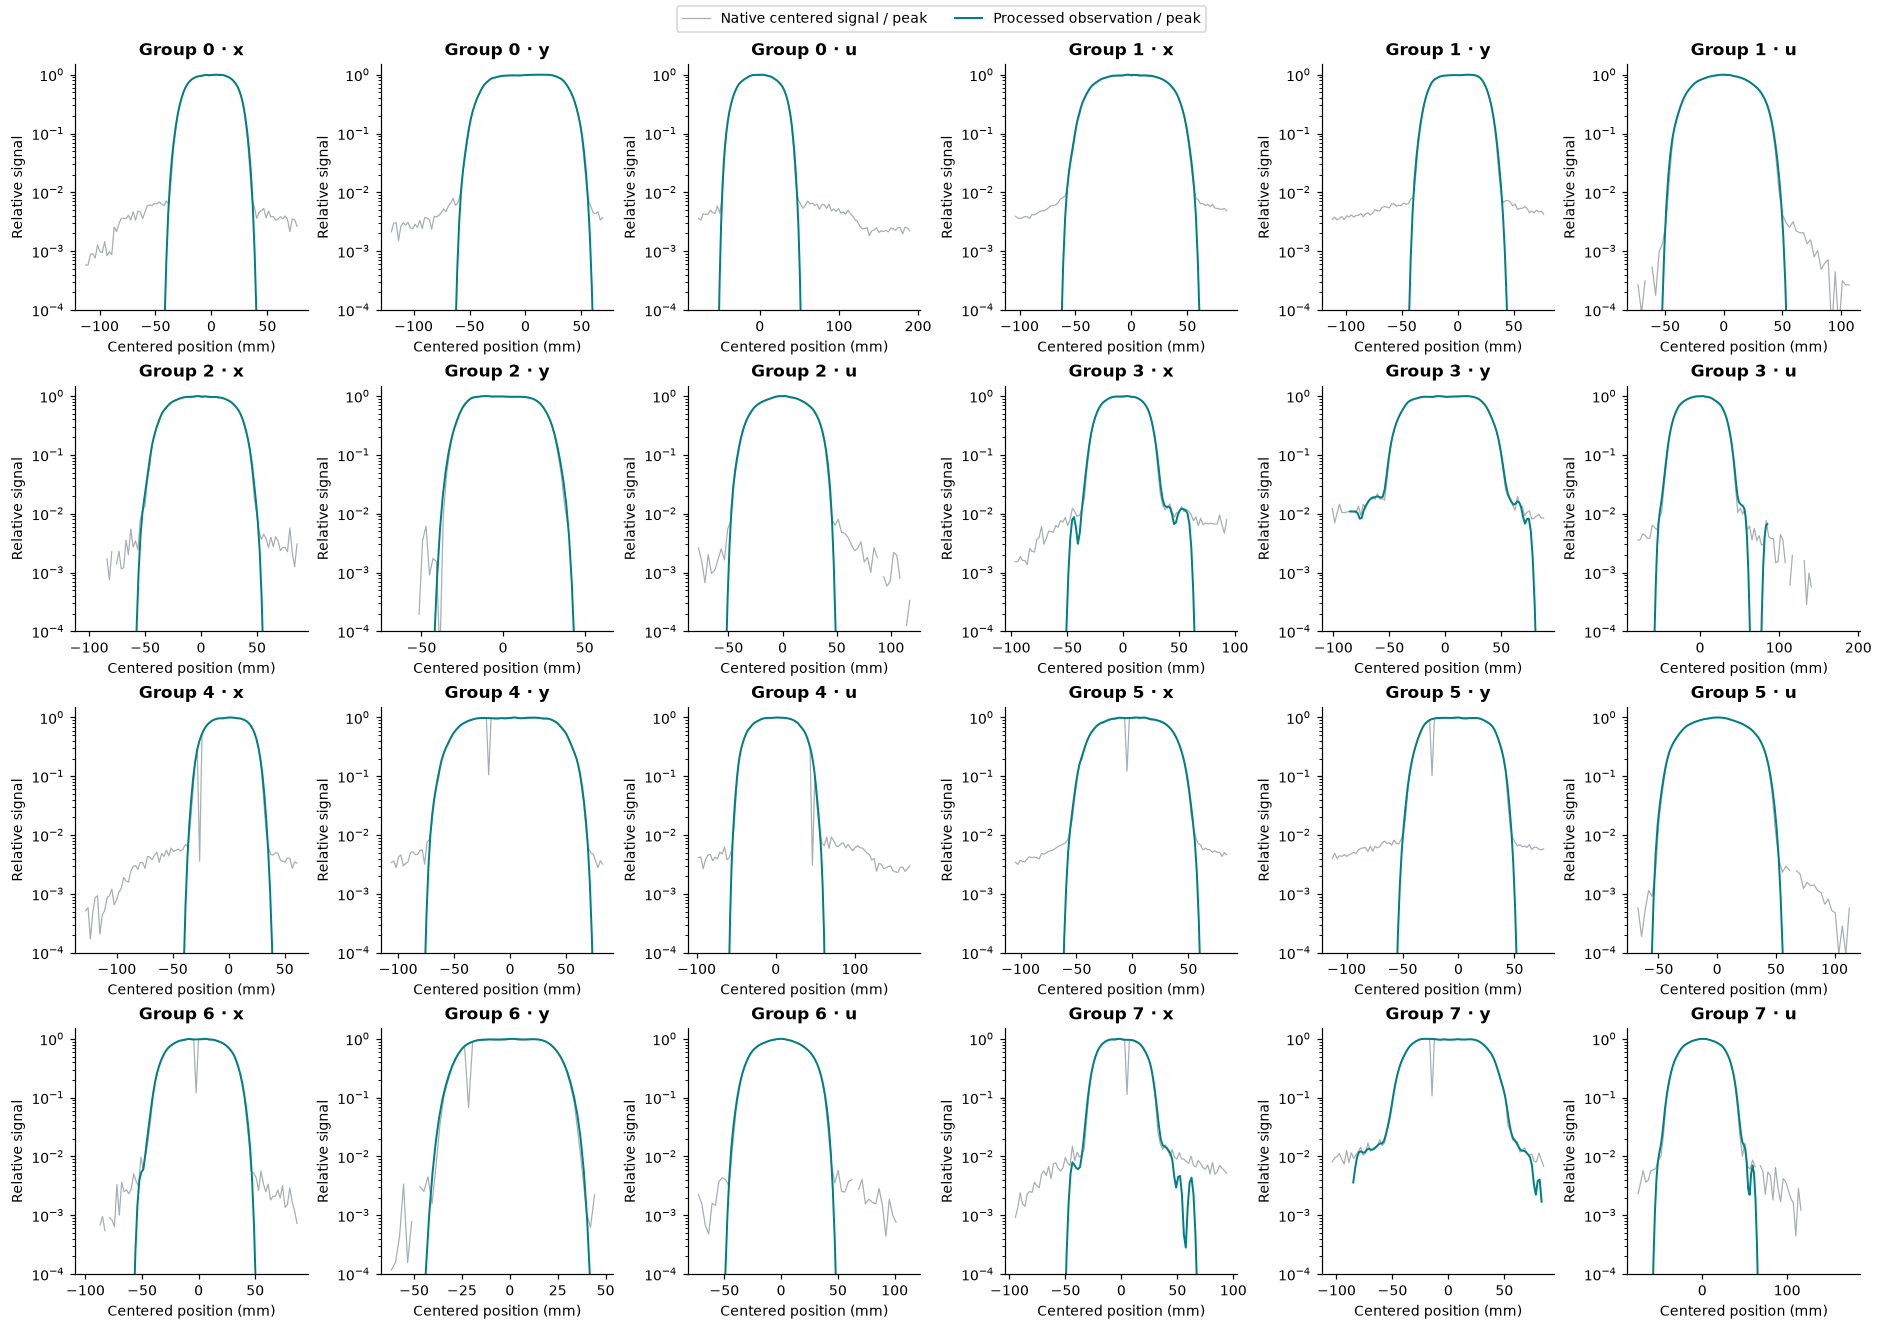

{'original_native_sample_counts': [[90, 90, 90], [90, 90, 90], [90, 90, 90], [90, 90, 90], [90, 90, 90], [90, 90, 90], [90, 90, 90], [90, 90, 90]], 'all_profile_integrals': [[1.0, 1.0, 1.0], [1.0, 1.0000000000000002, 1.0], [1.0, 1.0000000000000002, 0.9999999999999999], [1.0, 1.0000000000000002, 1.0], [0.9999999999999999, 0.9999999999999999, 0.9999999999999999], [1.0, 1.0, 0.9999999999999999], [1.0, 0.9999999999999997, 1.0], [1.0, 1.0000000000000002, 1.0]]}


In [2]:
display(vis.preprocessing_profiles(raw,measured,COORDS,log=False));plt.close()
display(vis.preprocessing_profiles(raw,measured,COORDS,log=True));plt.close()
print({'original_native_sample_counts':[[len(raw[f'm{k//4}_w{k%4}_{d}_counts']) for d in ['x','y','u']] for k in range(8)],
       'all_profile_integrals':(measured.sum(axis=-1)*(COORDS[1]-COORDS[0])).tolist()})

# 3. Physics

Let $x=(X,X',Y,Y')$ be centered physical phase-space coordinates and $z=Nx$ a dimensionless representation. The full covariance $\Sigma$ is freshly inferred by least squares from the 24 reported RMS observations and known transport matrices, including the cross-plane moment $(s_x^2+s_y^2)/2-s_u^2$.

$$N\Sigma N^{\mathsf T}=I,\qquad x=N^{-1}z,\qquad
f_x(x)=|\det N|\,m_v/h^4\quad\mathrm{for}\ Nx\in v.$$

Here $m_v$ is voxel probability, $h=8/35$ is normalized cell width and $f_x$ has units $\mathrm{mm}^{-2}\mathrm{mrad}^{-2}$. Transported positions are $dT_kN^{-1}z$, with horizontal, vertical and diagonal rows $d$. A uniform four-dimensional cell projects to the convolution of four uniform intervals. Point-mass projection would omit this source sampler's within-cell uniform distribution.

The original helper assigned sorted emittances to eigenvectors in a different order. It therefore failed its intended unit-covariance normalization. V2 pairs each actual eigenmode with its own emittance **inside the source basis construction**, before complete reconstruction. All other selected inverse parameters remain unchanged. The figure shows actual dimensionless covariance errors for V1, reproduced V2 and fresh extraction; it is not a fitted correction to the final density.

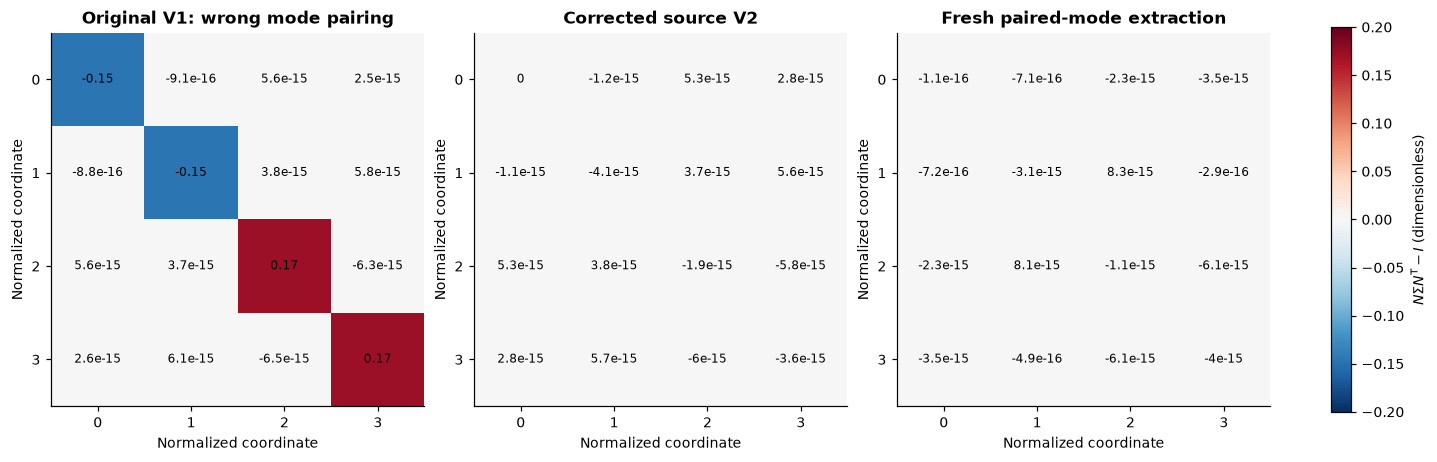

{'source_V1_diagonal': [0.8542718596639742, 0.8542718596639709, 1.1705875462096405, 1.1705875462096362], 'source_V2_max_error': 5.9639253332743265e-15, 'fresh_max_error': 8.266580274224159e-15}


In [3]:
display(vis.covariance_correction(S,old['normalization'][0],source['normalization'][0],fresh['normalization']));plt.close()
print({'source_V1_diagonal':np.diag(old['normalization'][0]@S@old['normalization'][0].T).tolist(),
       'source_V2_max_error':float(np.max(abs(source['normalization'][0]@S@source['normalization'][0].T-np.eye(4)))),
       'fresh_max_error':float(np.max(abs(fresh['normalization']@S@fresh['normalization'].T-np.eye(4))))})
assert np.max(abs(fresh['normalization']@S@fresh['normalization'].T-np.eye(4)))<1e-10

# 4. Method

The complete selected estimator multiplies a Gaussian prior by 24 one-dimensional Lagrange functions $H$. It evaluates the full 35 × 35 × 35 × 35 grid, draws one million particles for every projection update, and draws their coordinates uniformly inside their selected cells. The source option named noise=0 suppresses additional jitter, not the within-cell sampling.

For measured profile $g$ and current predicted profile $p$, the relaxed Gauss–Seidel update is

$$H_{\mathrm{new}}(s)=H(s)\left[1+0.2\left(\frac{g(s)}{p(s)}-1\right)\right].$$

The ratio is used only where both profiles are positive. All other positions retain ratio 1. Every sweep updates three directions at all eight transport groups, and the selected path performs all five sweeps without early stopping.

The local code caches fixed transported grid coordinates and uses explicit linear interpolation, Gaussian weights, sampling, histograms and multiplicative updates. It does not import the upstream MENT or phase-space libraries. A private historical common-random-number diagnostic recorded cross-runtime numerical agreement; it is not an automatic acceptance criterion. Current automated parity tests hold actual upstream particle coordinates fixed to check deterministic probability, projection, histogram and relaxation operations. The sampler is tested by unseeded distributional properties, while the full independent reconstruction is judged by the public physical conditions.

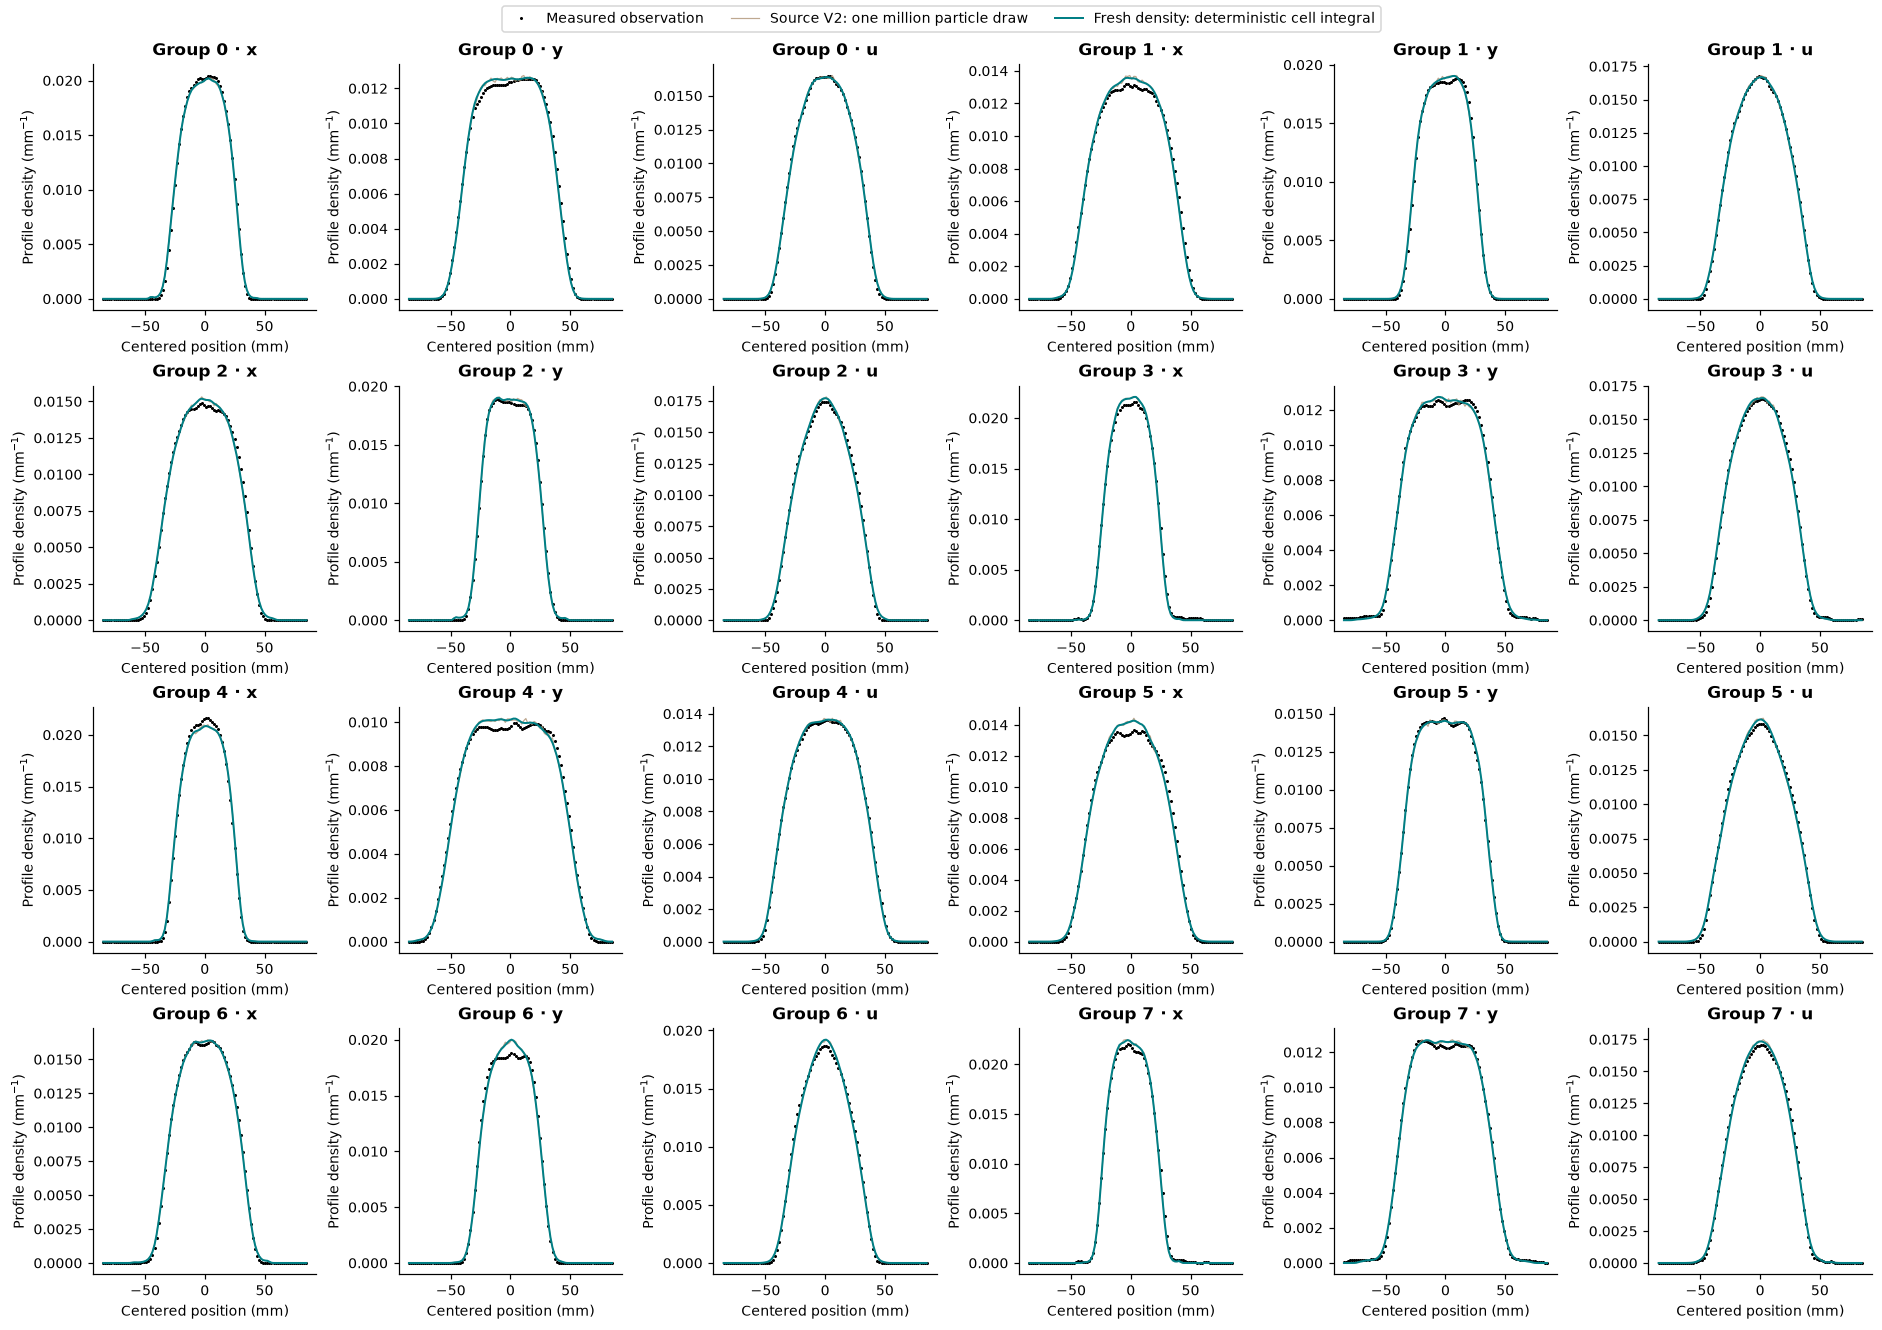

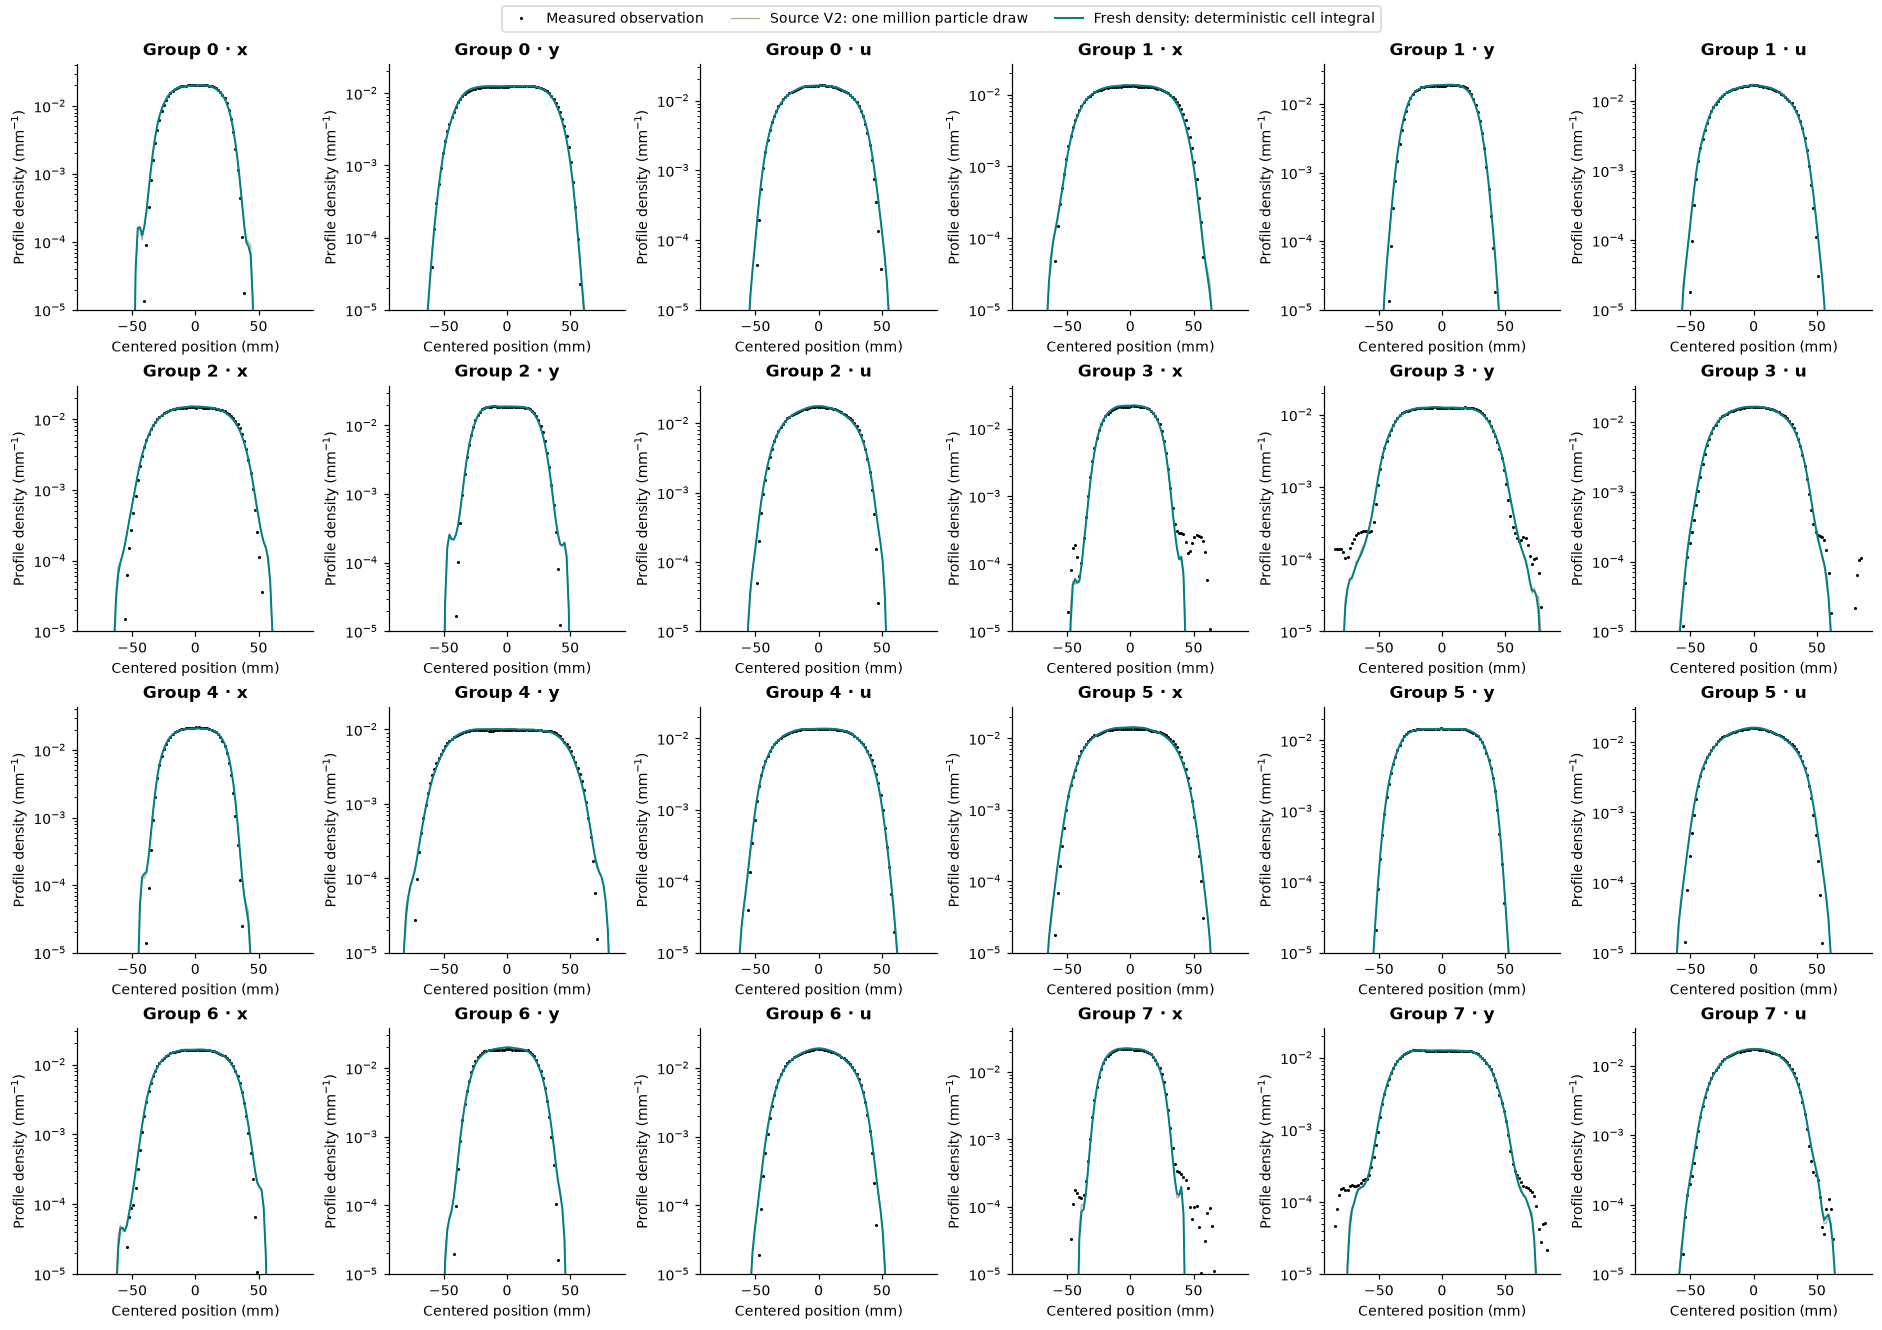

In [4]:
points=grid_points()
V=np.linalg.inv(fresh['normalization'])
directions=np.array([[1.,0,0,0],[0,0,1.,0],[1.,0,-1.,0]])/np.array([[1.],[1.],[np.sqrt(2)]])
def deterministic_profiles(mass,N,subdivisions=32):
    VV=np.linalg.inv(N)
    values=[]
    for k in range(8):
        values.append([judge.uniform_voxel_projection(mass.ravel(),points,d@T[k]@VV,COORDS,subdivisions) for d in directions])
    return np.asarray(values)
fresh_pred=deterministic_profiles(fresh['reconstruction'],fresh['normalization'])
source_pred=deterministic_profiles(source['reconstruction'][0],source['normalization'][0])
source_mc=np.asarray([[source_profiles[f'predicted_{k}_{j}'] for j in range(3)] for k in range(8)])
display(vis.fitted_profiles(measured,fresh_pred,source_mc,COORDS,log=False));plt.close()
display(vis.fitted_profiles(measured,fresh_pred,source_mc,COORDS,log=True));plt.close()

# 5. Results

The preceding profile plots retain all 24 groups in linear and logarithmic form. The brown source curve is an actual one-million-particle draw from the reproduced V2 fit. The fresh curve is a deterministic uniform-cell integral, so small differences include Monte Carlo plotting noise as well as inverse-state differences. The formal table below compares source and fresh densities using the **same deterministic operator**, separating those roles.

The entropy is discrete relative to normalized Gaussian midpoint weights $q_v$ on the finite cells:

$$D(m\|q)=\sum_{v:m_v>0}m_v\log(m_v/q_v).$$

It is not relabeled as independently measured physical truth or exact continuum entropy. Every profile has an individual bound. A Gaussian alone fits poorly; the reconstructed density must depart from it while remaining within the declared entropy bound.

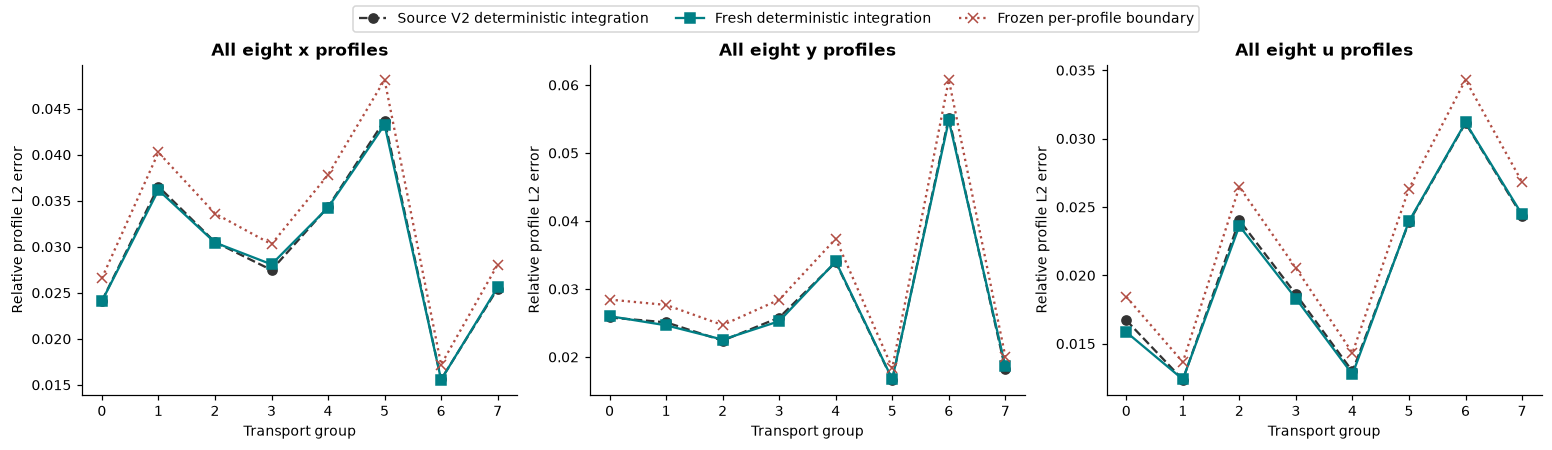

| Metric | Reproduced source V2 | Fresh local V2 |
| --- | --- | --- |
| Mean of24profile relative L2 | 0.02604310836 | 0.02594834797 |
| Worst profile relative L2 | 0.05519881141 | 0.05478763532 |
| Discrete KL | 0.3073711771 | 0.3070978435 |
| Whitening max error | 5.963925333e-15 | 8.266580274e-15 |

{
  "fresh_metrics": {
    "normalization_abs_error": 1.1102230246251565e-16,
    "negative_probability_max": 0.0,
    "whitening_max_abs_error": 8.266580274224159e-15,
    "relative_entropy_KL": 0.3070978434532865,
    "profile_00_relative_l2": 0.024099158984491983,
    "profile_01_relative_l2": 0.02600886552736423,
    "profile_02_relative_l2": 0.01585006204434452,
    "profile_03_relative_l2": 0.03616895379463035,
    "profile_04_relative_l2": 0.02466273037858718,
    "profile_05_relative_l2": 0.012395335652822196,
    "profile_06_relative_l2": 0.030462389402645784,
    "profile_07_relative_l2": 0.022561488691513486,
    "profile_08_relative_l2": 0.0236219762212522,
    "profile_09_relative_l2": 0.028094302321206396,
    "profile_10_relative_l2": 0.025270042800827074,
    "profile_11_relative_l2": 0.018307076231207493,
    "profile_12_relative_l2": 0.034265214006296396,
    "profile_13_relative_l2": 0.03405204988482629,
    "profile_14_relative_l2": 0.01275894576266891,
    "profile

In [5]:
fresh_metrics=judge.score(fresh['reconstruction'],fresh['normalization'],observed,T,S)
source_metrics=judge.score(source['reconstruction'][0],source['normalization'][0],observed,T,S)
assert all(fresh_metrics[k]<=thresholds[k]['boundary'] for k in fresh_metrics)
source_errors=[source_metrics[f'profile_{i:02d}_relative_l2'] for i in range(24)]
fresh_errors=[fresh_metrics[f'profile_{i:02d}_relative_l2'] for i in range(24)]
bounds=[thresholds[f'profile_{i:02d}_relative_l2']['boundary'] for i in range(24)]
display(vis.metric_profiles(source_errors,fresh_errors,bounds));plt.close()
lines=['| Metric | Reproduced source V2 | Fresh local V2 |','| --- | --- | --- |']
for label,aa,bb in [('Mean of24profile relative L2',np.mean(source_errors),np.mean(fresh_errors)),('Worst profile relative L2',max(source_errors),max(fresh_errors)),('Discrete KL',source_metrics['relative_entropy_KL'],fresh_metrics['relative_entropy_KL']),('Whitening max error',source_metrics['whitening_max_abs_error'],fresh_metrics['whitening_max_abs_error'])]:
    lines.append(f'| {label} | {aa:.10g} | {bb:.10g} |')
display(Markdown('\n'.join(lines)))
print(json.dumps({'fresh_metrics':fresh_metrics,'all_required_conditions_pass':True},indent=2))

Both physical and normalized corner plots below preserve the four one-dimensional marginals, all six two-dimensional planes and 2-RMS ellipses of the Gaussian prior and fresh distribution. They use the original 65-bin visualization resolution and a central 3.5 prior-RMS display window. This display window does not crop the output or evaluation.

Each source and fresh density is resampled with one million particles by the local uniform-cell sampler **for visualization only**. The source density itself is the archived reproduced upstream result. Fresh maps are colored; black source contours are 10%,50% and 90% of their panel's peak. Dotted brown Gaussian curves/ellipses are prior comparisons, not ground truth. Solid white map ellipses show the fresh 2-RMS covariance. Finite histogram sampling makes small map differences stochastic.

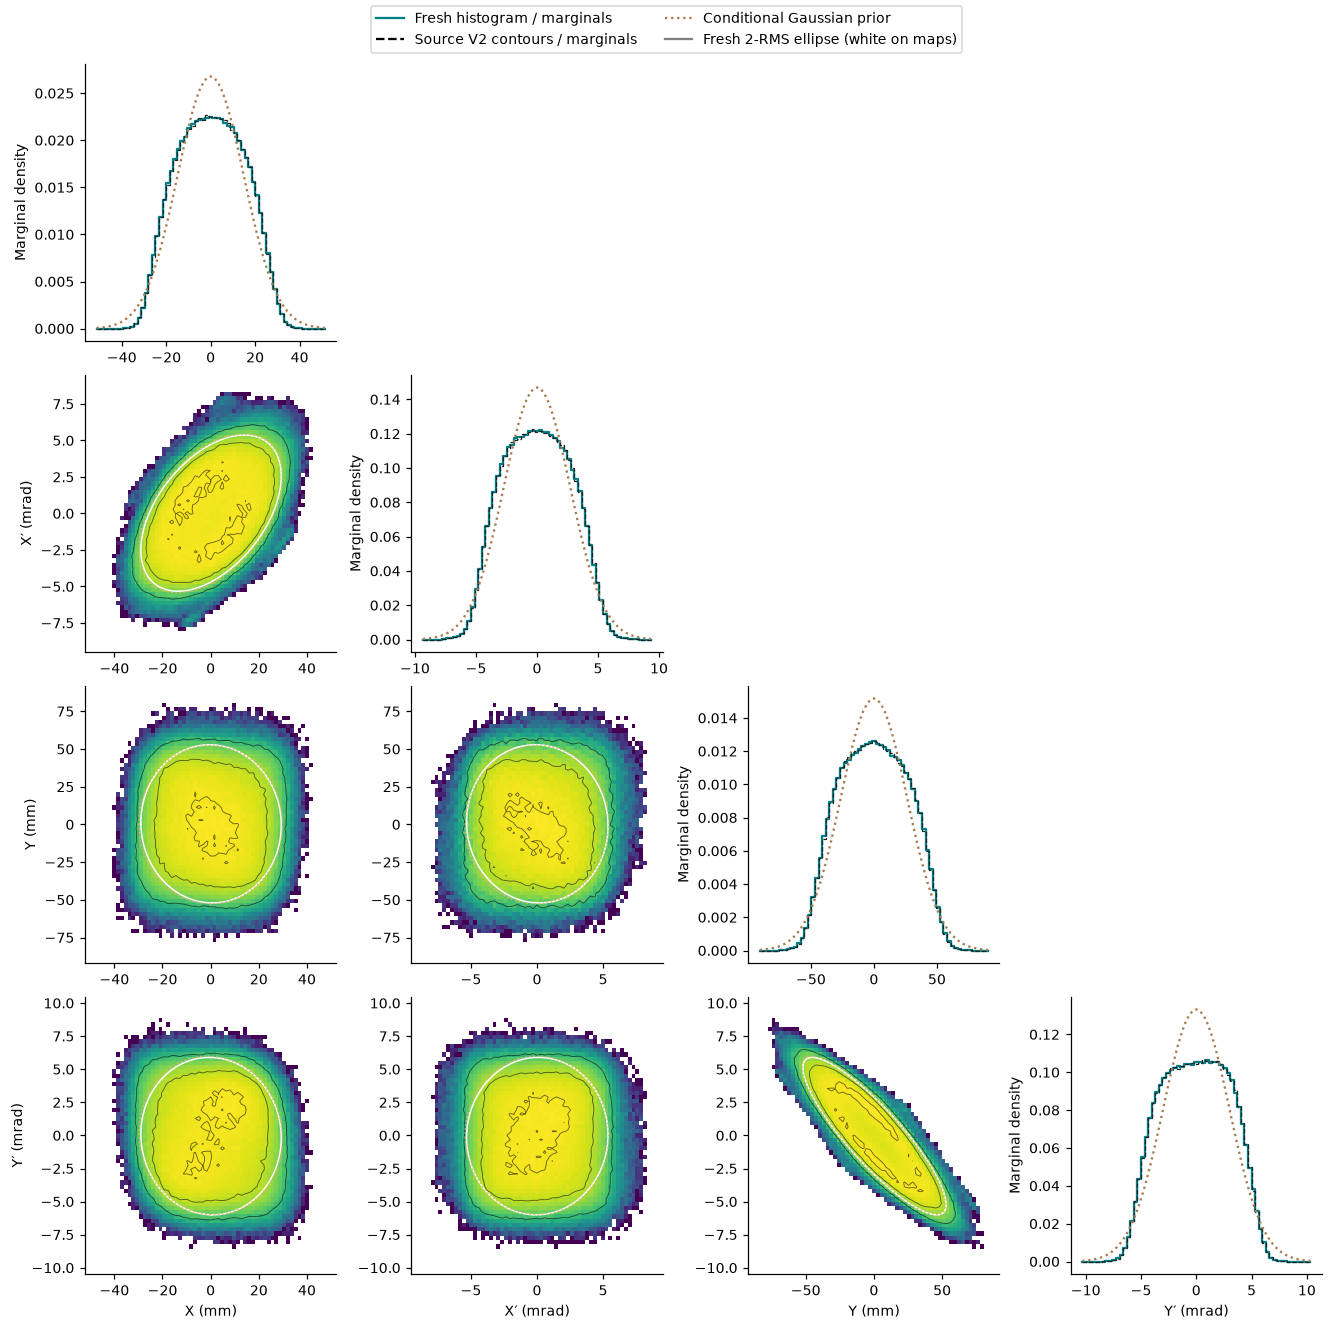

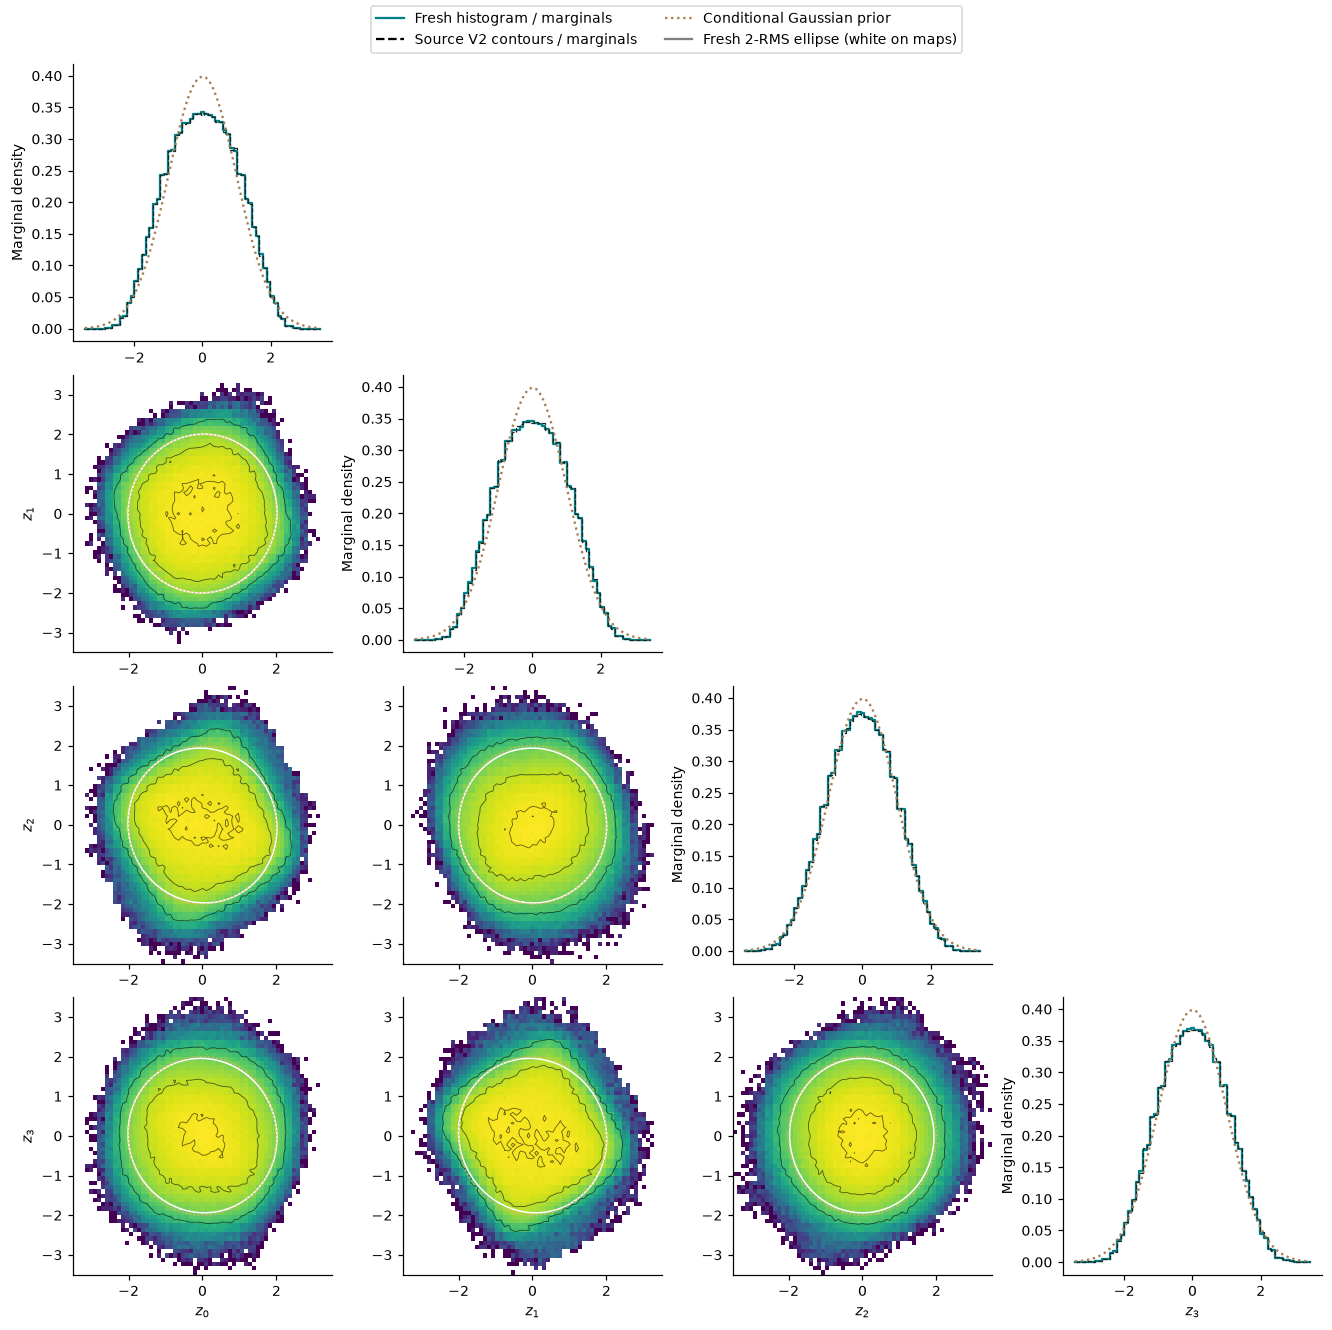

| Original diagnostic definition | Actual reproduced source V2, one million particles | Fresh local V2, one million particles |
| --- | --- | --- |
| Mean absolute profile discrepancy (inverse mm) | 0.0001587940192 | 0.0001584548324 |
| Projected horizontal RMS emittance (mm mrad) | 34.36959972 | 34.36292112 |
| Projected vertical RMS emittance (mm mrad) | 38.36393432 | 38.35929859 |
| Larger intrinsic RMS emittance (mm mrad) | 38.58770597 | 38.54651065 |
| Smaller intrinsic RMS emittance (mm mrad) | 34.03956853 | 34.07236421 |

{'same_MAE_with_deterministic_cell_integrals': {'source_V2': 0.00015638125322554836, 'fresh_V2': 0.0001557224582155365}}


In [6]:
fresh_z=sample_grid(fresh['reconstruction'].ravel(),1000000,np.random.default_rng(7301))
source_z=sample_grid(source['reconstruction'].ravel(),1000000,np.random.default_rng(7302))
fresh_x=fresh_z@V.T
source_x=source_z@np.linalg.inv(source['normalization'][0]).T
display(vis.corner(fresh_x,source_x,S,normalized=False));plt.close()
display(vis.corner(fresh_z,source_z,np.eye(4),normalized=True));plt.close()
fresh_mc=np.asarray([[simulated_profile(fresh_z,V,M,j) for j in range(3)] for M in T])
fresh_author_metrics=emittances(np.cov(fresh_x,rowvar=False))
fresh_author_metrics['discrepancy']=float(np.mean(abs(fresh_mc-measured)))
names=[('discrepancy','Mean absolute profile discrepancy (inverse mm)'),('eps_x','Projected horizontal RMS emittance (mm mrad)'),('eps_y','Projected vertical RMS emittance (mm mrad)'),('eps_1','Larger intrinsic RMS emittance (mm mrad)'),('eps_2','Smaller intrinsic RMS emittance (mm mrad)')]
table=['| Original diagnostic definition | Actual reproduced source V2, one million particles | Fresh local V2, one million particles |','| --- | --- | --- |']
for key,label in names:table.append(f"| {label} | {float(source_eval[key]):.10g} | {fresh_author_metrics[key]:.10g} |")
display(Markdown('\n'.join(table)))
print({'same_MAE_with_deterministic_cell_integrals':{'source_V2':float(np.mean(abs(source_pred-measured))),'fresh_V2':float(np.mean(abs(fresh_pred-measured)))}})
del fresh_x,source_x,fresh_z,source_z

The table preserves all five numeric diagnostics of the author's evaluation callback, separately from the benchmark's relative-L 2 and normalized-KL criteria. Mean absolute discrepancy has units inverse mm and is not relabeled as relative error. Projected RMS emittances are square roots of the horizontal/vertical covariance determinants; intrinsic emittances follow the two positive symplectic eigenvalues. They are geometric quantities in mm mrad, with no extra factor of $\pi$. Their Monte Carlo covariance uses every sampled particle, independently of the displayed 3.5-RMS window. Source and fresh random draws differ, so small finite-sample diagnostic differences are expected.

The entire five-sweep path is checked next. Sweep 0 is the Gaussian multiplied by the measured support functions, rather than an unconstrained Gaussian. Every displayed state is reconstructed from its fresh Lagrange functions and evaluated against all 24 observations; no missing method is filled by a cached final density.

The V1 reconstruction is intentionally excluded from this corrected-prior entropy trajectory: its coordinate scaling produced a different physical Gaussian prior. Its original result and actual normalization error remain documented above. No V1 likelihood, density threshold or entropy value was reused to set V2 acceptance.

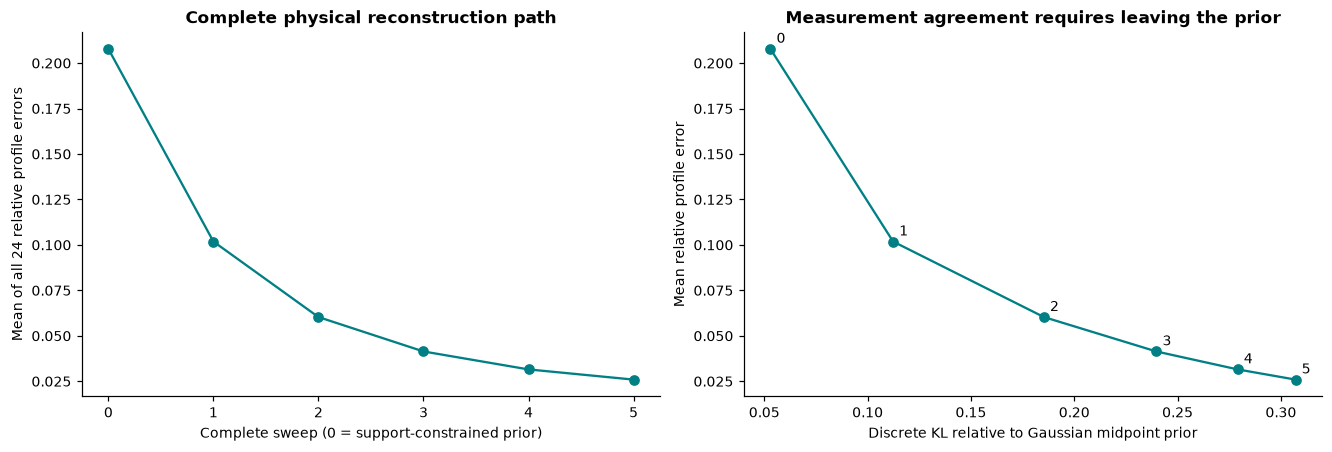

{'all_fresh_sweep_measurements': [{'KL': 0.052946018386520376, 'mean_error': 0.2078315037906303, 'worst_error': 0.2582299292264344}, {'KL': 0.11233566290512781, 'mean_error': 0.1018727037990238, 'worst_error': 0.15909852634223798}, {'KL': 0.18529411306841906, 'mean_error': 0.060347660492460854, 'worst_error': 0.11604073524183389}, {'KL': 0.23971782156759436, 'mean_error': 0.041429235428176905, 'worst_error': 0.08871255915766356}, {'KL': 0.2790872949884362, 'mean_error': 0.03154761198360659, 'worst_error': 0.06856496616834122}, {'KL': 0.3070978434532865, 'mean_error': 0.025948347965443375, 'worst_error': 0.054787635315816936}]}


In [7]:
transported=projected_coordinates(points,V,T)
prior=np.exp(-.5*np.sum(points*points,axis=1))/(2*np.pi)**2
rows=[]
for H in fresh['history']:
    p=probability(H,transported,prior);m=(p/p.sum()).reshape((35,)*4)
    metric=judge.score(m,fresh['normalization'],observed,T,S)
    errors=[metric[f'profile_{i:02d}_relative_l2'] for i in range(24)]
    rows.append({'KL':metric['relative_entropy_KL'],'mean_error':float(np.mean(errors)),'worst_error':float(max(errors))})
display(vis.entropy_tradeoff(rows));plt.close()
print({'all_fresh_sweep_measurements':rows})
del transported,points

# 6. Conclusion

The actively reconstructed full four-dimensional density satisfies every individual projection constraint, the probability conditions, the entropy bound and the freshly inferred coordinate-consistency condition. Original V2 and fresh measurements agree under the same deterministic integration protocol. The complete five-sweep budget and one-million-particle update size were preserved.

Independent tests expose the original normal-mode scaling error, establish the corrected covariance condition on distinct nondegenerate examples, verify uniform-cell projection moments and grid refinement, and compare deterministic update operators on frozen particle inputs while testing sampler distributions. These checks establish extraction fidelity and a physically stated conditional inverse result. They do not establish a uniquely measured four-dimensional true density. Finite support, the Gaussian prior and the limited projection set remain substantive modeling assumptions.